# Lab 3 — homework

Dzienny dataset do prognozowania liczby kursów yellow taxi (NYC, 2024). Pipeline w Polars (lazy), wynik: `homework/dataset.parquet`.

## Konfiguracja

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

LAB03 = Path.cwd()
if LAB03.name == "homework":
    LAB03 = LAB03.parent
DATA_DIR = LAB03 / "data"
OUT_PARQUET = LAB03 / "homework" / "dataset.parquet"

MONEY_COLS = [
    "fare_amount",
    "extra",
    "mta_tax",
    "tip_amount",
    "tolls_amount",
    "improvement_surcharge",
    "total_amount",
    "congestion_surcharge",
    "Airport_fee",
]

VALID_VENDOR = (1, 2, 6, 7)
VALID_RATECODE = (1, 2, 3, 4, 5, 6)
PAYMENT_LABELS = ("card", "cash", "other")
BOROUGHS = (
    "Bronx",
    "Brooklyn",
    "EWR",
    "Manhattan",
    "Queens",
    "Staten Island",
    "Unknown",
)

## 1. Wczytanie danych

In [2]:
def read_taxi_zones(data_dir: Path) -> pl.LazyFrame:
    return (
        pl.scan_csv(data_dir / "taxi_zone_lookup.csv")
        .with_columns(
            pl.when(pl.col("Borough") == "N/A")
            .then(pl.lit("Unknown"))
            .otherwise(pl.col("Borough"))
            .cast(pl.Enum(BOROUGHS))
            .alias("Borough")
        )
        .select(
            pl.col("LocationID").cast(pl.UInt16),
            pl.col("Borough"),
        )
    )


def read_trips(data_dir: Path) -> pl.LazyFrame:
    scans = []
    for month in range(1, 13):
        lf = pl.scan_parquet(data_dir / f"{month}.parquet")
        lf = lf.with_columns(
            pl.col("tpep_pickup_datetime").dt.cast_time_unit("us"),
            pl.col("tpep_dropoff_datetime").dt.cast_time_unit("us"),
        )
        scans.append(lf)

    end_2025 = pl.datetime(2025, 1, 1)

    return (
        pl.concat(scans)
        .filter(
            pl.col("tpep_pickup_datetime").dt.year() == 2024,
            pl.col("tpep_dropoff_datetime") < end_2025,
        )
        .with_columns(
            pl.col("VendorID").cast(pl.UInt8),
            pl.col("RatecodeID").cast(pl.UInt8),
            pl.col("passenger_count").cast(pl.UInt8),
            pl.col("payment_type").cast(pl.UInt8),
            pl.col("PULocationID").cast(pl.UInt16),
            pl.col("DOLocationID").cast(pl.UInt16),
            *[pl.col(c).cast(pl.Float32) for c in MONEY_COLS],
            pl.col("trip_distance").cast(pl.Float32),
        )
        .select(
            "VendorID",
            "RatecodeID",
            "passenger_count",
            "payment_type",
            "PULocationID",
            "DOLocationID",
            "tpep_pickup_datetime",
            "tpep_dropoff_datetime",
            "trip_distance",
            *MONEY_COLS,
        )
    )

In [3]:
zones = read_taxi_zones(DATA_DIR)
trips_raw = read_trips(DATA_DIR)
print(trips_raw.explain())

 WITH_COLUMNS:
 [col("VendorID").strict_cast(UInt8), col("RatecodeID").strict_cast(UInt8), col("passenger_count").strict_cast(UInt8), col("payment_type").strict_cast(UInt8), col("PULocationID").strict_cast(UInt16), col("DOLocationID").strict_cast(UInt16), col("fare_amount").strict_cast(Float32), col("extra").strict_cast(Float32), col("mta_tax").strict_cast(Float32), col("tip_amount").strict_cast(Float32), col("tolls_amount").strict_cast(Float32), col("improvement_surcharge").strict_cast(Float32), col("total_amount").strict_cast(Float32), col("congestion_surcharge").strict_cast(Float32), col("Airport_fee").strict_cast(Float32), col("trip_distance").strict_cast(Float32)] 
  UNION
    PLAN 0:
      FILTER [([(col("tpep_dropoff_datetime")) < (2025-01-01 00:00:00)]) & ([(col("tpep_pickup_datetime").dt.year()) == (2024)])] FROM
         WITH_COLUMNS:
         [col("tpep_pickup_datetime").dt.cast_time_unit(), col("tpep_dropoff_datetime").dt.cast_time_unit()] 
          Parquet SCAN [/home/wom

## 2. Czyszczenie i filtrowanie

In [4]:
def clean(lf: pl.LazyFrame) -> pl.LazyFrame:
    lf = lf.with_columns(
        pl.col("passenger_count").fill_null(1),
        pl.col("congestion_surcharge").fill_null(0),
        pl.col("Airport_fee").fill_null(0),
    )
    lf = lf.with_columns(
        pl.col("passenger_count").clip(upper_bound=6),
        *[pl.col(c).abs().alias(c) for c in MONEY_COLS],
        (pl.col("tpep_dropoff_datetime") - pl.col("tpep_pickup_datetime"))
        .dt.total_minutes()
        .alias("trip_minutes"),
    )

    over_money = pl.lit(False)
    for c in MONEY_COLS:
        over_money = over_money | (pl.col(c) > 1000)

    return lf.filter(
        pl.col("passenger_count") >= 1,
        pl.col("trip_minutes") > 0,
        pl.col("trip_minutes") <= 120,
        ~over_money,
        pl.col("VendorID").is_in(VALID_VENDOR),
        pl.col("RatecodeID").is_in(VALID_RATECODE),
    )

In [5]:
trips_clean = clean(trips_raw)
# podgląd skali (może chwilę potrwać)
n_after = trips_clean.select(pl.len()).collect().item()
print(f"Wiersze po czyszczeniu: {n_after:,}")

Wiersze po czyszczeniu: 35,714,035


## 3. Transformacja

In [6]:
def transform(lf: pl.LazyFrame, zones: pl.LazyFrame) -> pl.LazyFrame:
    payment = (
        pl.when(pl.col("payment_type") == 1)
        .then(pl.lit("card"))
        .when(pl.col("payment_type") == 2)
        .then(pl.lit("cash"))
        .otherwise(pl.lit("other"))
        .cast(pl.Enum(PAYMENT_LABELS))
        .alias("payment")
    )

    pu = zones.rename({"Borough": "pickup_borough"})
    do = zones.rename({"LocationID": "DOLocationID", "Borough": "dropoff_borough"})

    pickup_dt = pl.col("tpep_pickup_datetime")
    minute = pickup_dt.dt.hour() * 60 + pickup_dt.dt.minute()
    weekday = pickup_dt.dt.weekday()  # pon=1 … nd=7
    morning = (minute >= 390) & (minute <= 570)
    evening = (minute >= 930) & (minute < 1200)
    is_weekday = weekday <= 5

    return (
        lf.with_columns(payment)
        .join(pu, left_on="PULocationID", right_on="LocationID", how="left")
        .join(do, on="DOLocationID", how="left")
        .with_columns(
            pl.col("pickup_borough").fill_null(pl.lit("Unknown")),
            pl.col("dropoff_borough").fill_null(pl.lit("Unknown")),
            (pl.col("Airport_fee") > 0).alias("is_airport_ride"),
            (is_weekday & (morning | evening)).alias("is_rush_hour"),
        )
        .drop("PULocationID", "DOLocationID", "payment_type", "VendorID", "RatecodeID")
    )

## 4. Cechy dzienne (agregacja)

In [7]:
def _dummy(col: str, value: str, prefix: str) -> pl.Expr:
    return (
        (pl.col(col) == value)
        .cast(pl.UInt32)
        .alias(f"{prefix}_{value.lower().replace(' ', '_')}")
    )


def extract_features(lf: pl.LazyFrame) -> pl.LazyFrame:
    payment_dummies = [_dummy("payment", p, "pay") for p in PAYMENT_LABELS]
    pickup_dummies = [_dummy("pickup_borough", b, "pu") for b in BOROUGHS]
    dropoff_dummies = [_dummy("dropoff_borough", b, "do") for b in BOROUGHS]

    lf = lf.with_columns(
        pl.col("tpep_pickup_datetime").dt.date().alias("date"),
        *payment_dummies,
        *pickup_dummies,
        *dropoff_dummies,
        ((pl.col("payment") == "card").cast(pl.UInt32) * pl.col("total_amount")).alias(
            "amount_card"
        ),
        ((pl.col("payment") == "cash").cast(pl.UInt32) * pl.col("total_amount")).alias(
            "amount_cash"
        ),
        ((pl.col("payment") == "other").cast(pl.UInt32) * pl.col("total_amount")).alias(
            "amount_other"
        ),
        pl.col("is_airport_ride").cast(pl.UInt32),
        pl.col("is_rush_hour").cast(pl.UInt32),
    )

    pay_cols = [f"pay_{p}" for p in PAYMENT_LABELS]
    pu_cols = [f"pu_{b.lower().replace(' ', '_')}" for b in BOROUGHS]
    do_cols = [f"do_{b.lower().replace(' ', '_')}" for b in BOROUGHS]

    agg = [
        pl.len().alias("rides_total"),
        pl.col("is_airport_ride").sum().alias("rides_airport"),
        pl.col("is_rush_hour").sum().alias("rides_rush_hour"),
        pl.col("fare_amount").mean().alias("fare_amount_mean"),
        pl.col("trip_distance").median().alias("trip_distance_median"),
        pl.col("total_amount").sum().alias("total_amount_sum"),
        pl.col("amount_card").sum().alias("total_amount_card"),
        pl.col("amount_cash").sum().alias("total_amount_cash"),
        pl.col("amount_other").sum().alias("total_amount_other"),
        pl.col("congestion_surcharge").sum().alias("congestion_surcharge_sum"),
        pl.col("passenger_count").sum().alias("passengers_total"),
        pl.col("date").first().dt.quarter().alias("quarter"),
        pl.col("date").first().dt.month().alias("month"),
        pl.col("date").first().dt.day().alias("day_of_month"),
        pl.col("date").first().dt.weekday().alias("day_of_week"),
        (pl.col("date").first().dt.weekday() >= 6).alias("is_weekend"),
        *[
            pl.col(c).sum().alias(f"rides_payment_{c.removeprefix('pay_')}")
            for c in pay_cols
        ],
        *[
            pl.col(c).sum().alias(f"rides_pickup_{c.removeprefix('pu_')}")
            for c in pu_cols
        ],
        *[
            pl.col(c).sum().alias(f"rides_dropoff_{c.removeprefix('do_')}")
            for c in do_cols
        ],
    ]

    return (
        lf.group_by("date")
        .agg(agg)
        .select(
            "date",
            "rides_total",
            "rides_airport",
            "rides_rush_hour",
            "fare_amount_mean",
            "trip_distance_median",
            "total_amount_sum",
            "total_amount_card",
            "total_amount_cash",
            "total_amount_other",
            "congestion_surcharge_sum",
            "passengers_total",
            "quarter",
            "month",
            "day_of_month",
            "day_of_week",
            "is_weekend",
            *[f"rides_payment_{p}" for p in PAYMENT_LABELS],
            *[f"rides_pickup_{b.lower().replace(' ', '_')}" for b in BOROUGHS],
            *[f"rides_dropoff_{b.lower().replace(' ', '_')}" for b in BOROUGHS],
        )
    )

## Pipeline i zapis

In [8]:
dataset = (
    read_trips(DATA_DIR)
    .pipe(clean)
    .pipe(transform, zones)
    .pipe(extract_features)
    .sort("date")
    .collect()
)

OUT_PARQUET.parent.mkdir(parents=True, exist_ok=True)
dataset.write_parquet(OUT_PARQUET)
print(f"Zapisano {OUT_PARQUET}, shape={dataset.shape}")

Zapisano /home/womackow/CODE_SPACE/agh/sem2/UMISI-sem2-MLops/lab03/homework/dataset.parquet, shape=(366, 34)


## 5. Analiza

In [9]:
from IPython.display import display

print("shape:", dataset.shape)
display(dataset.head())
display(dataset.describe())
print(dataset.schema)

shape: (366, 34)


date,rides_total,rides_airport,rides_rush_hour,fare_amount_mean,trip_distance_median,total_amount_sum,total_amount_card,total_amount_cash,total_amount_other,congestion_surcharge_sum,passengers_total,quarter,month,day_of_month,day_of_week,is_weekend,rides_payment_card,rides_payment_cash,rides_payment_other,rides_pickup_bronx,rides_pickup_brooklyn,rides_pickup_ewr,rides_pickup_manhattan,rides_pickup_queens,rides_pickup_staten_island,rides_pickup_unknown,rides_dropoff_bronx,rides_dropoff_brooklyn,rides_dropoff_ewr,rides_dropoff_manhattan,rides_dropoff_queens,rides_dropoff_staten_island,rides_dropoff_unknown
date,u32,u32,u32,f32,f32,f32,f64,f64,f64,f32,i64,i8,i8,i8,i8,bool,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
2024-01-01,68198,8159,0,21.894104,2.13,2.1197e6,1.6967e6,375693.09122,47221.580124,154545.0,106874,1,1,1,1,false,52230,14162,1806,46,552,3,58428,8895,1,273,545,3710,370,57814,4820,28,911
2024-01-02,70326,9629,0,21.110575,1.83,2.16296e6,1.7284e6,391583.411381,42908.43,159400.0,101177,1,1,2,2,false,53595,15116,1615,27,209,7,59535,10295,1,252,426,2958,308,61651,4240,29,714
2024-01-03,77331,8983,0,19.79714,1.75,2.2478e6,1.7970e6,407376.761362,43327.87013,176757.5,108191,1,1,3,3,false,59776,15874,1681,33,270,3,67089,9631,0,305,483,3094,267,68699,4003,13,772
2024-01-04,96840,8106,0,18.505037,1.75,2.6727e6,2.1851e6,436565.151126,50963.330183,225275.0,133035,1,1,4,4,false,77143,17687,2010,33,228,3,87482,8719,1,374,587,3060,218,88059,4085,14,817
2024-01-05,96860,7312,0,17.945797,1.71,2600508.5,2.1384e6,411157.391187,50884.850042,226075.0,134644,1,1,5,5,false,77366,17367,2127,37,268,1,88266,7908,0,380,527,2862,217,88463,3919,19,853


statistic,date,rides_total,rides_airport,rides_rush_hour,fare_amount_mean,trip_distance_median,total_amount_sum,total_amount_card,total_amount_cash,total_amount_other,congestion_surcharge_sum,passengers_total,quarter,month,day_of_month,day_of_week,is_weekend,rides_payment_card,rides_payment_cash,rides_payment_other,rides_pickup_bronx,rides_pickup_brooklyn,rides_pickup_ewr,rides_pickup_manhattan,rides_pickup_queens,rides_pickup_staten_island,rides_pickup_unknown,rides_dropoff_bronx,rides_dropoff_brooklyn,rides_dropoff_ewr,rides_dropoff_manhattan,rides_dropoff_queens,rides_dropoff_staten_island,rides_dropoff_unknown
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""366""",366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0
"""null_count""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""","""2024-07-01 12:00:00""",97579.330601,8784.740437,0.0,19.596518,1.727118,2.8140e6,2.3818e6,363362.122434,68699.175616,228522.265625,131837.601093,2.505464,6.513661,15.756831,3.986339,0.284153,80493.248634,14576.887978,2509.193989,35.674863,348.191257,1.904372,87349.699454,9526.054645,1.781421,316.02459,446.177596,3506.45082,270.551913,87839.601093,4650.740437,24.379781,841.428962
"""std""",null,15117.156519,1681.92083,0.0,1.180161,0.107704,450376.03125,419424.993751,35543.841407,15943.321714,37707.59375,18542.235401,1.119551,3.455958,8.823592,2.006108,null,13968.225082,1332.471882,507.895554,11.66241,123.630964,1.724643,15036.654456,1699.267006,1.26113,56.316639,58.775483,546.38203,69.33351,14542.026836,631.818394,6.629575,109.47313
"""min""","""2024-01-01""",46105.0,3239.0,0.0,16.431631,1.5,1.2761e6,958765.51841,235548.82074,32957.480051,106777.5,72305.0,1.0,1.0,1.0,1.0,0.0,33267.0,10037.0,1304.0,13.0,149.0,0.0,41121.0,4499.0,0.0,157.0,300.0,1640.0,116.0,41026.0,2490.0,9.0,460.0
"""25%""","""2024-04-01""",87314.0,7691.0,0.0,18.777067,1.66,2.4999e6,2.0886e6,343772.310808,57515.230165,201608.5,119091.0,2.0,4.0,8.0,2.0,null,71033.0,13781.0,2163.0,28.0,259.0,1.0,76272.0,8424.0,1.0,277.0,406.0,3149.0,224.0,77523.0,4245.0,19.0,777.0
"""50%""","""2024-07-02""",98082.0,8813.0,0.0,19.581633,1.7,2.816872e6,2.3897e6,367104.5908,69214.620187,231397.5,131297.0,3.0,7.0,16.0,4.0,null,81806.0,14625.0,2493.0,34.0,321.0,2.0,88693.0,9488.0,2.0,316.0,439.0,3469.0,261.0,89151.0,4670.0,24.0,840.0
"""75%""","""2024-10-01""",108364.0,9931.0,0.0,20.358126,1.78,3118727.5,2.6629e6,390858.120974,79892.380125,255372.5,143799.0,4.0,10.0,23.0,6.0,null,89995.0,15469.0,2827.0,41.0,404.0,3.0,98298.0,10636.0,2.0,349.0,482.0,3842.0,319.0,98088.0,5108.0,29.0,911.0
"""max""","""2024-12-31""",138340.0,14609.0,0.0,24.056139,2.25,4.339979e6,3.8173e6,438725.641235,108588.020199,327985.0,195851.0,4.0,12.0,31.0,7.0,1.0,118717.0,17687.0,4020.0,111.0,873.0,14.0,126610.0,15374.0,6.0,489.0,645.0,5482.0,550.0,125995.0,6196.0,48.0,1206.0


Schema({'date': Date, 'rides_total': UInt32, 'rides_airport': UInt32, 'rides_rush_hour': UInt32, 'fare_amount_mean': Float32, 'trip_distance_median': Float32, 'total_amount_sum': Float32, 'total_amount_card': Float64, 'total_amount_cash': Float64, 'total_amount_other': Float64, 'congestion_surcharge_sum': Float32, 'passengers_total': Int64, 'quarter': Int8, 'month': Int8, 'day_of_month': Int8, 'day_of_week': Int8, 'is_weekend': Boolean, 'rides_payment_card': UInt32, 'rides_payment_cash': UInt32, 'rides_payment_other': UInt32, 'rides_pickup_bronx': UInt32, 'rides_pickup_brooklyn': UInt32, 'rides_pickup_ewr': UInt32, 'rides_pickup_manhattan': UInt32, 'rides_pickup_queens': UInt32, 'rides_pickup_staten_island': UInt32, 'rides_pickup_unknown': UInt32, 'rides_dropoff_bronx': UInt32, 'rides_dropoff_brooklyn': UInt32, 'rides_dropoff_ewr': UInt32, 'rides_dropoff_manhattan': UInt32, 'rides_dropoff_queens': UInt32, 'rides_dropoff_staten_island': UInt32, 'rides_dropoff_unknown': UInt32})


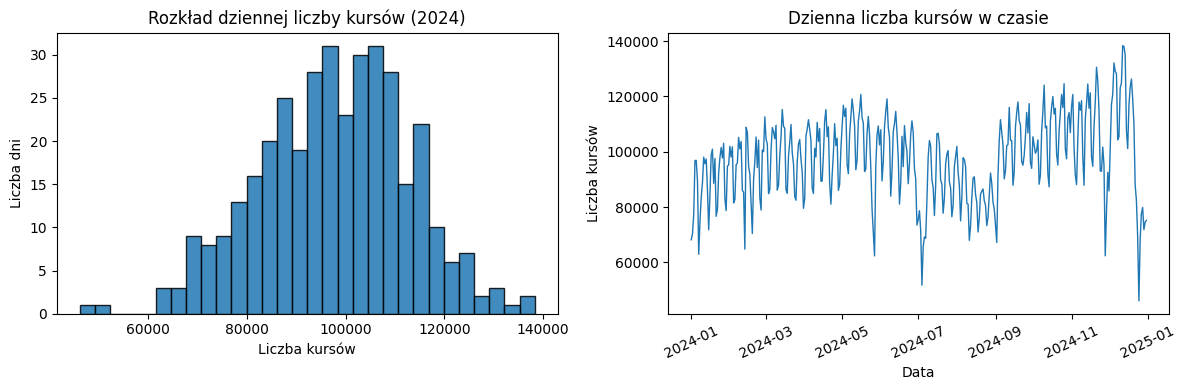

In [10]:
pdf = dataset.sort("date").to_pandas()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(pdf["rides_total"], bins=30, edgecolor="black", alpha=0.85)
axes[0].set_title("Rozkład dziennej liczby kursów (2024)")
axes[0].set_xlabel("Liczba kursów")
axes[0].set_ylabel("Liczba dni")

axes[1].plot(pdf["date"], pdf["rides_total"], linewidth=1)
axes[1].set_title("Dzienna liczba kursów w czasie")
axes[1].set_xlabel("Data")
axes[1].set_ylabel("Liczba kursów")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()